# Etapa 1 · Dados

| | |
|---|---|
| **Pergunta** | Em que cenário de teste vamos provar que um especialista pequeno substitui uma LLM? |
| **Entrada** | Nenhuma: é a primeira etapa. A escolha do dataset vem do `PLANO.md`. |
| **Entrega** | `entregas/01_dados/`: três partições em Parquet, o inventário de rótulos, as figuras e um resumo. |
| **Pronto quando** | As contagens batem com o artigo, a conversão para BIO não perde informação e a entrega recarrega idêntica. |

**Artigo-âncora:** FitzGerald et al., *MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages* ([arXiv 2204.08582](https://arxiv.org/abs/2204.08582)).

**Roteiro**

1. O cenário
2. Obter o dado bruto
3. Olhar um registro
4. Da anotação para BIO
5. Conferir contra o artigo
6. Intenções: o que o modelo vai classificar
7. Entidades: o que o modelo vai extrair
8. Tamanho e vocabulário
9. Armadilhas
10. Entrega
11. Resposta

A lógica mora em `src/especialista/dados/massive.py`. Este notebook só chama, mostra e explica.

In [1]:
import json
import platform
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
from IPython.display import HTML, Markdown, display

from especialista import visual
from especialista.caminhos import RAIZ, entrega
from especialista.dados import massive

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 120)

PASTA = entrega("01_dados")


def n(x):
    """Inteiro com separador de milhar: 11.514."""
    return f"{int(x):,}".replace(",", ".")


def pct(x):
    """Fração como porcentagem: 6,7%."""
    return f"{x:.1%}".replace(".", ",")

## 1. O cenário

O problema é o subagente de compreensão de um assistente. Ele recebe o pedido do usuário e devolve duas coisas:

- a **intenção**: qual ação executar (num agente, qual ferramenta chamar);
- as **entidades**: os trechos do pedido que são os argumentos dessa ação.

Hoje isso costuma ser feito por uma LLM com um prompt. Para testar se um modelo pequeno dá conta, precisamos de pedidos reais com as duas respostas anotadas por pessoas.

O **Amazon MASSIVE, no recorte pt-PT**, atende a isso:

- cada enunciado tem intenção e entidades anotadas por humanos;
- há resultados publicados no mesmo conjunto de teste, o que dá uma régua externa;
- a licença é CC BY 4.0.

Duas ressalvas acompanham o projeto do começo ao fim: o texto é português **europeu**, e é um benchmark público que simula o subagente, não o log de um agente real.

## 2. Obter o dado bruto

O download vem do endereço oficial da Amazon. O hash do arquivo fica fixado no código: se o arquivo mudar, a etapa falha em vez de trocar os dados sem aviso.

In [2]:
tarball = massive.baixar()
jsonl = massive.extrair_locale(tarball)
bruto = massive.ler_bruto(jsonl)

print(f"Fonte    {massive.URL}")
print(f"Arquivo  {tarball.relative_to(RAIZ)}  ({tarball.stat().st_size / 1e6:.1f} MB)")
print(f"SHA-256  {massive.SHA256}  (conferido)")
print(f"Locale   {massive.LOCALE}: {n(len(bruto))} enunciados, {len(bruto.columns)} campos")

Fonte    https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz
Arquivo  data/raw/amazon-massive-dataset-1.1.tar.gz  (40.3 MB)
SHA-256  4cba5faa11c71437928e17cb1b9b3d8b8e727e7ea363a3a9a8045e19c0491577  (conferido)
Locale   pt-PT: 16.521 enunciados, 10 campos


## 3. Olhar um registro

Antes de transformar qualquer coisa, um registro como ele veio:

In [3]:
registro = bruto.iloc[0].to_dict()
registro["judgments"] = [registro["judgments"][0], "... (3 avaliadores por enunciado)"]
print(json.dumps(registro, ensure_ascii=False, indent=2))

{
  "id": "0",
  "locale": "pt-PT",
  "partition": "test",
  "scenario": "alarm",
  "intent": "alarm_set",
  "utt": "acorda-me às cinco da manhã durante esta semana",
  "annot_utt": "acorda-me às [time : cinco da manhã] durante [date : esta semana]",
  "worker_id": "8",
  "slot_method": [
    {
      "slot": "time",
      "method": "translation"
    },
    {
      "slot": "date",
      "method": "translation"
    }
  ],
  "judgments": [
    {
      "worker_id": "2",
      "intent_score": 1,
      "slots_score": 1,
      "grammar_score": 4,
      "spelling_score": 1,
      "language_identification": "target"
    },
    "... (3 avaliadores por enunciado)"
  ]
}


Os campos que importam para o projeto:

| Campo | O que é | Uso |
|---|---|---|
| `utt` | o enunciado | entrada do modelo |
| `intent` | a intenção | alvo da cabeça de intenção |
| `annot_utt` | o enunciado com as entidades marcadas como `[tipo : texto]` | alvo da cabeça de entidades, depois de convertido |
| `scenario` | o domínio (alarme, agenda, música...) | análise |
| `partition` | `train`, `dev` ou `test` | separação oficial |
| `judgments` | nota de 3 avaliadores sobre intenção, entidades e gramática | medir ruído dos rótulos |

## 4. Da anotação para BIO

Um modelo que rotula entidades precisa de **um rótulo por palavra**, e a anotação do MASSIVE marca trechos. A conversão padrão é o esquema BIO:

- `B-tipo`: primeira palavra de uma entidade;
- `I-tipo`: continuação da mesma entidade;
- `O`: palavra fora de qualquer entidade.

O `B` existe para separar duas entidades do mesmo tipo que apareçam lado a lado.

A unidade aqui é a **palavra separada por espaço**, como no próprio MASSIVE. Quebrar a palavra em pedaços menores é decisão da arquitetura, na Etapa 3.

In [4]:
df = massive.preparar(bruto)
rotulos = massive.construir_rotulos(df)

treino = df[df["partition"] == "train"]
teste = df[df["partition"] == "test"]


def mostrar(linha):
    display(HTML(
        f'<div style="font-family:monospace;font-size:12px;margin-top:10px;">intent = {linha.intent}</div>'
        + visual.html_bio(linha.tokens, linha.tags)
    ))


exemplos = [
    df.iloc[0],                                 # o exemplo do começo do notebook
    treino[treino["n_slots"] == 0].iloc[0],     # sem entidade
    treino[treino["n_slots"] >= 3].iloc[0],     # várias entidades
]
for linha in exemplos:
    mostrar(linha)

Cada palavra tem a sua tag embaixo; as palavras com fundo pertencem a uma entidade.

A conversão só serve se não perder nada. O teste é fazer o caminho de volta, de tokens e tags para a anotação original, em todos os enunciados:

In [5]:
volta = df.apply(lambda r: massive.bio_para_anotacao(r.tokens, r.tags), axis=1)
original = df["annot_utt"].str.split().str.join(" ")  # só normaliza espaços
ida_e_volta = (volta == original).mean()

print(f"Enunciados convertidos:        {n(len(df))}")
print(f"Tokens iguais a utt.split():   100,0%  (preparar() falha se não for)")
print(f"Ida e volta idêntica:          {pct(ida_e_volta)}")

Enunciados convertidos:        16.521
Tokens iguais a utt.split():   100,0%  (preparar() falha se não for)
Ida e volta idêntica:          100,0%


## 5. Conferir contra o artigo

O primeiro critério de pronto: os números obtidos precisam ser os publicados por FitzGerald et al.

In [6]:
obtido = {
    **df["partition"].value_counts().to_dict(),
    "intents": len(rotulos["intents"]),
    "slot_types": len(rotulos["slot_types"]),
    "scenarios": len(rotulos["scenarios"]),
}
conferencia = pd.DataFrame({"publicado": massive.PUBLICADO, "obtido": obtido})
conferencia["bate"] = (conferencia["publicado"] == conferencia["obtido"]).map({True: "sim", False: "NÃO"})
conferencia.index = ["enunciados de treino", "enunciados de validação (dev)", "enunciados de teste",
                     "intenções", "tipos de entidade", "cenários"]
conferencia

,publicado,obtido,bate
enunciados de treino,11514,11514,sim
enunciados de validação (dev),2033,2033,sim
enunciados de teste,2974,2974,sim
intenções,60,60,sim
tipos de entidade,55,55,sim
cenários,18,18,sim


## 6. Intenções: o que o modelo vai classificar

São 60 intenções agrupadas em 18 cenários. Primeiro os cenários, depois as intenções.

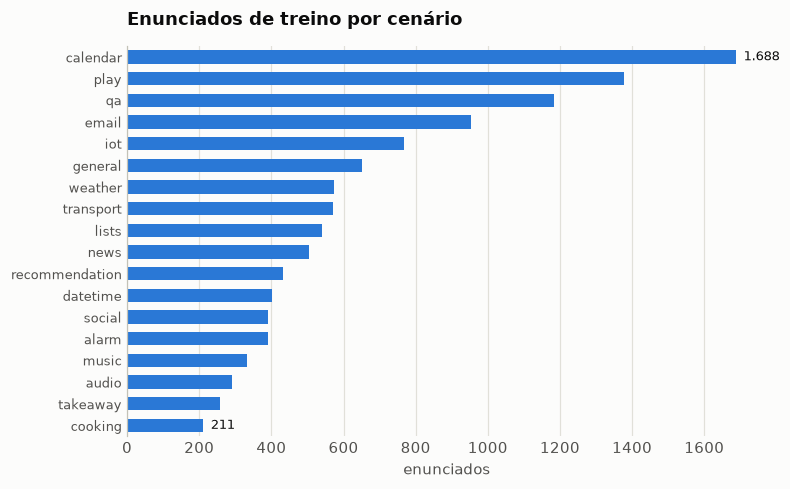

In [7]:
por_cenario = treino["scenario"].value_counts()
fig, ax = visual.barras_ranqueadas(
    por_cenario, "Enunciados de treino por cenário", "enunciados",
    destacar={por_cenario.idxmax(): n(por_cenario.max()), por_cenario.idxmin(): n(por_cenario.min())},
)
visual.salvar(fig, PASTA, "cenarios")
plt.show()

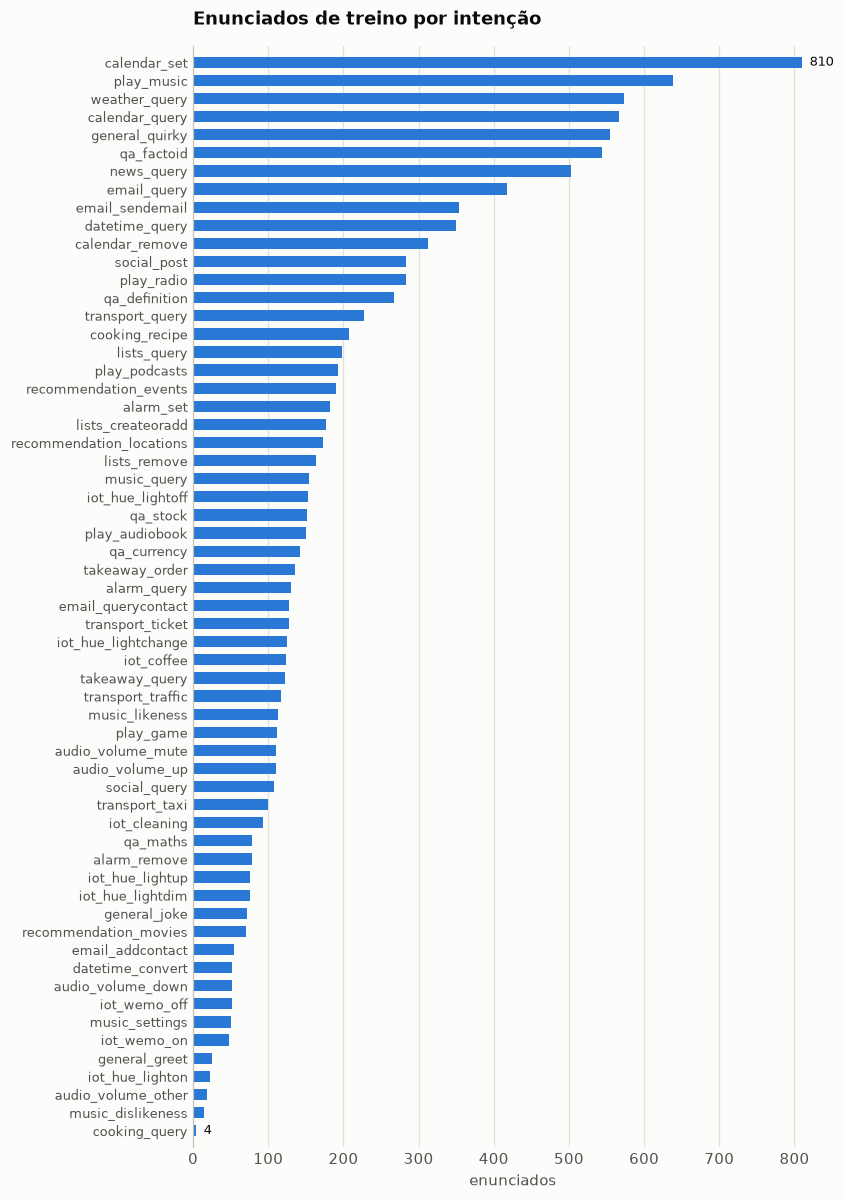

In [8]:
por_intencao = treino["intent"].value_counts()
fig, ax = visual.barras_ranqueadas(
    por_intencao, "Enunciados de treino por intenção", "enunciados",
    destacar={por_intencao.idxmax(): n(por_intencao.max()), por_intencao.idxmin(): n(por_intencao.min())},
)
visual.salvar(fig, PASTA, "intencoes")
plt.show()

In [9]:
raras = por_intencao[por_intencao < 50]
display(Markdown(f"""
**Leitura.** As classes são bem desbalanceadas:

- a maior intenção (`{por_intencao.idxmax()}`) tem {n(por_intencao.max())} exemplos de treino; a menor (`{por_intencao.idxmin()}`) tem {n(por_intencao.min())};
- {len(raras)} das 60 intenções têm menos de 50 exemplos: {", ".join(f"`{i}` ({v})" for i, v in raras.items())};
- as 10 maiores intenções somam {pct(por_intencao.head(10).sum() / len(treino))} do treino.

Consequência para a avaliação: acurácia sozinha esconde o erro nas intenções raras, então a Etapa 2 vai reportar também o macro-F1.
"""))


**Leitura.** As classes são bem desbalanceadas:

- a maior intenção (`calendar_set`) tem 810 exemplos de treino; a menor (`cooking_query`) tem 4;
- 6 das 60 intenções têm menos de 50 exemplos: `iot_wemo_on` (48), `general_greet` (25), `iot_hue_lighton` (22), `audio_volume_other` (18), `music_dislikeness` (14), `cooking_query` (4);
- as 10 maiores intenções somam 46,1% do treino.

Consequência para a avaliação: acurácia sozinha esconde o erro nas intenções raras, então a Etapa 2 vai reportar também o macro-F1.


## 7. Entidades: o que o modelo vai extrair

São 55 tipos de entidade. Em BIO isso vira 111 tags: `O`, mais um `B-` e um `I-` para cada tipo.

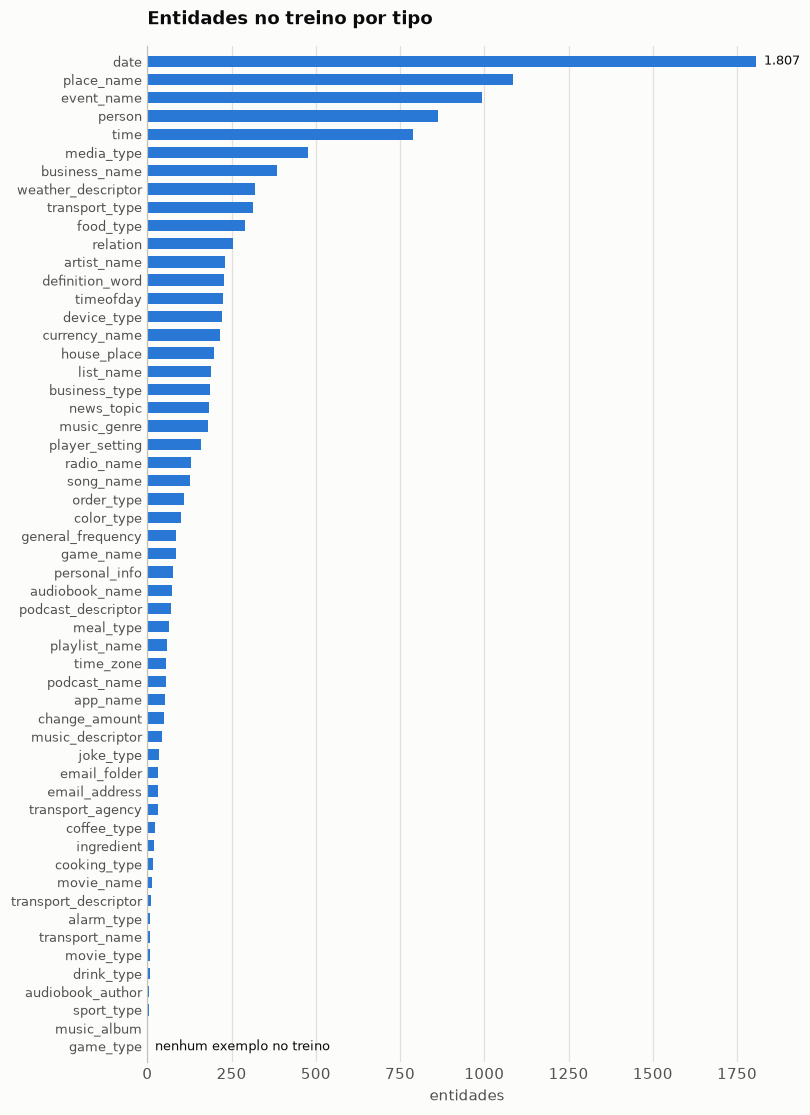

In [10]:
tipos_no_treino = pd.Series([tipo for tags in treino["tags"] for tipo, _, _ in massive.bio_para_spans(tags)])
por_tipo = tipos_no_treino.value_counts().reindex(rotulos["slot_types"], fill_value=0)
sem_exemplo = list(por_tipo[por_tipo == 0].index)

fig, ax = visual.barras_ranqueadas(
    por_tipo, "Entidades no treino por tipo", "entidades",
    destacar={por_tipo.idxmax(): n(por_tipo.max()), **{t: "nenhum exemplo no treino" for t in sem_exemplo}},
)
visual.salvar(fig, PASTA, "entidades")
plt.show()

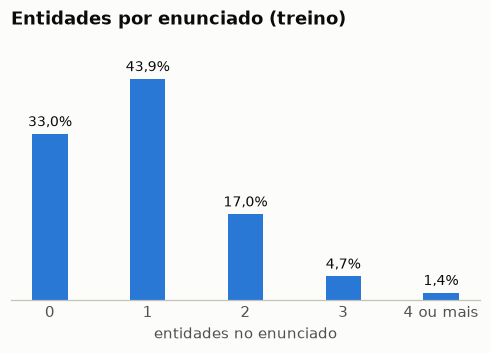

In [11]:
faixas = treino["n_slots"].clip(upper=4).value_counts(normalize=True).sort_index()
faixas.index = ["0", "1", "2", "3", "4 ou mais"]

fig, ax = plt.subplots(figsize=(5.5, 3))
barras = ax.bar(faixas.index, faixas.values, width=0.36, color=visual.AZUL)
ax.bar_label(barras, labels=[pct(v) for v in faixas.values], padding=3, fontsize=9)
ax.set_title("Entidades por enunciado (treino)")
ax.set_xlabel("entidades no enunciado")
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)
ax.margins(y=0.15)
visual.salvar(fig, PASTA, "entidades_por_enunciado")
plt.show()

In [12]:
tamanho_entidade = pd.Series([fim - ini for tags in treino["tags"] for _, ini, fim in massive.bio_para_spans(tags)])
tokens_fora = sum(tag == "O" for tags in treino["tags"] for tag in tags) / treino["n_tokens"].sum()
tipos_raros = por_tipo[por_tipo < 20]

display(Markdown(f"""
**Leitura.**

- {pct((treino["n_slots"] == 0).mean())} dos enunciados de treino não têm nenhuma entidade: o modelo precisa saber devolver "nada".
- {pct(tokens_fora)} das palavras do treino têm tag `O`. Acertar a tag palavra por palavra é fácil e enganoso; por isso a métrica de entidades conta a **entidade inteira**, com tipo e limites corretos.
- As entidades são curtas: {pct((tamanho_entidade == 1).mean())} têm uma palavra só, a média é de {f"{tamanho_entidade.mean():.1f}".replace(".", ",")} e a maior tem {tamanho_entidade.max()}.
- A cauda é longa: {len(tipos_raros)} dos 55 tipos têm menos de 20 exemplos no treino.
- Tipos sem nenhum exemplo no treino: {", ".join(f"`{t}`" for t in sem_exemplo) or "nenhum"}.
"""))


**Leitura.**

- 33,0% dos enunciados de treino não têm nenhuma entidade: o modelo precisa saber devolver "nada".
- 75,9% das palavras do treino têm tag `O`. Acertar a tag palavra por palavra é fácil e enganoso; por isso a métrica de entidades conta a **entidade inteira**, com tipo e limites corretos.
- As entidades são curtas: 59,1% têm uma palavra só, a média é de 1,8 e a maior tem 11.
- A cauda é longa: 11 dos 55 tipos têm menos de 20 exemplos no treino.
- Tipos sem nenhum exemplo no treino: `game_type`.


## 8. Tamanho e vocabulário

Dois números daqui entram direto no desenho da rede na Etapa 3: o tamanho dos enunciados e quanto do vocabulário de teste o treino cobre.

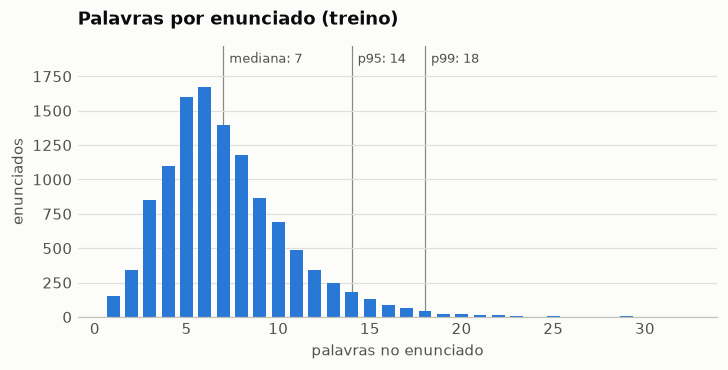

In [13]:
contagem = treino["n_tokens"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(contagem.index, contagem.values, width=0.7, color=visual.AZUL)
ax.set_title("Palavras por enunciado (treino)")
ax.set_xlabel("palavras no enunciado")
ax.set_ylabel("enunciados")
ax.yaxis.grid(True)
ax.spines["left"].set_visible(False)
topo = contagem.max() * 1.18
ax.set_ylim(0, topo)
for q, nome in ((0.5, "mediana"), (0.95, "p95"), (0.99, "p99")):
    v = treino["n_tokens"].quantile(q)
    ax.axvline(v, color=visual.TINTA_SUAVE, linewidth=0.8, zorder=0.5)
    ax.annotate(f"{nome}: {v:.0f}", (v, topo), xytext=(4, -11), textcoords="offset points",
                fontsize=8.5, color=visual.TINTA_SECUNDARIA)
visual.salvar(fig, PASTA, "tamanho")
plt.show()

In [14]:
vocabulario = {t for tokens in treino["tokens"] for t in tokens}
tokens_novos = sum(t not in vocabulario for tokens in teste["tokens"] for t in tokens) / teste["n_tokens"].sum()
enunciados_com_novo = teste["tokens"].map(lambda ts: any(t not in vocabulario for t in ts)).mean()

caracteres = sorted({c for texto in df["utt"] for c in texto})
nao_letras = [c for c in caracteres if not c.isalpha() and c != " "]
com_maiuscula = (df["utt"] != df["utt"].str.lower()).sum()

display(Markdown(f"""
**Leitura.**

- Os enunciados são curtos: mediana de {treino["n_tokens"].median():.0f} palavras, 99% com até {treino["n_tokens"].quantile(0.99):.0f}, máximo de {treino["n_tokens"].max()} no treino e {df["n_tokens"].max()} no conjunto todo.
- O treino tem {n(len(vocabulario))} palavras distintas.
- No teste, {pct(tokens_novos)} das palavras nunca apareceram no treino, e {pct(enunciados_com_novo)} dos enunciados têm pelo menos uma palavra nova. Uma rede treinada do zero com vocabulário de palavras inteiras fica cega nesses casos; é o argumento para olhar dentro da palavra (n-gramas de caracteres, como no DIET).
- O texto usa {len(caracteres)} caracteres distintos. Enunciados com letra maiúscula: {com_maiuscula}. Caracteres que não são letra: {" ".join(f"`{c}`" for c in nao_letras)}.
"""))


**Leitura.**

- Os enunciados são curtos: mediana de 7 palavras, 99% com até 18, máximo de 32 no treino e 70 no conjunto todo.
- O treino tem 6.220 palavras distintas.
- No teste, 4,0% das palavras nunca apareceram no treino, e 21,3% dos enunciados têm pelo menos uma palavra nova. Uma rede treinada do zero com vocabulário de palavras inteiras fica cega nesses casos; é o argumento para olhar dentro da palavra (n-gramas de caracteres, como no DIET).
- O texto usa 46 caracteres distintos. Enunciados com letra maiúscula: 0. Caracteres que não são letra: `'` `-` `.` `<` `´` `’`.


## 9. Armadilhas

Quatro coisas que os dados têm e que mudam a leitura dos resultados. Nenhuma é corrigida aqui: as partições ficam como publicadas, para os números continuarem comparáveis com a literatura. Elas são medidas e marcadas.

### 9.1 Texto de teste que também está no treino

In [15]:
triplas_de_treino = set(zip(treino["utt"], treino["intent"], treino["annot_utt"]))
linhas = []
for particao in ("dev", "test"):
    parte = df[df["partition"] == particao]
    repetidos = parte[parte["utt_in_train"]]
    mesmo_rotulo = sum((r.utt, r.intent, r.annot_utt) in triplas_de_treino for r in repetidos.itertuples())
    linhas.append({
        "partição": particao,
        "enunciados": n(len(parte)),
        "texto também no treino": f"{n(len(repetidos))} ({pct(len(repetidos) / len(parte))})",
        "... com o mesmo rótulo": n(mesmo_rotulo),
        "... com rótulo diferente": n(len(repetidos) - mesmo_rotulo),
    })
repeticao = pd.DataFrame(linhas).set_index("partição")
repeticao

,enunciados,texto também no treino,... com o mesmo rótulo,... com rótulo diferente
partição,,,,
dev,2.033,"143 (7,0%)",133,10
test,2.974,"199 (6,7%)",175,24


Parte do teste é memorizável. A coluna `utt_in_train` da entrega marca esses casos, e as etapas seguintes podem reportar o resultado também só nos enunciados inéditos.

### 9.2 O mesmo texto com intenções diferentes

In [16]:
intencoes_por_texto = df.groupby("utt")["intent"].agg(lambda s: sorted(set(s)))
ambiguos = intencoes_por_texto[intencoes_por_texto.map(len) > 1]
print(f"{len(ambiguos)} textos aparecem com mais de uma intenção. Exemplos:")
ambiguos.head(5).rename("intenções anotadas").to_frame()

31 textos aparecem com mais de uma intenção. Exemplos:


,intenções anotadas
utt,
abrir email,"[email_query, email_sendemail]"
apagar,"[calendar_remove, lists_remove]"
apagar as luzes,"[iot_hue_lightoff, iot_hue_lightup]"
boa noite,"[audio_volume_mute, general_greet, iot_hue_lightoff]"
calculadora,"[qa_definition, qa_maths]"


Esses casos definem um teto: nenhum modelo que só lê o texto acerta as duas anotações.

### 9.3 Quanto os avaliadores concordam com os rótulos

No MASSIVE, 3 avaliadores julgaram cada enunciado localizado. A tabela mostra em quantos enunciados todos os 3, ou pelo menos 2, confirmaram o rótulo.

In [17]:
concordancia = pd.DataFrame({
    "intenção: 3 de 3": df.groupby("partition")["intent_agreement"].apply(lambda s: pct((s == 3).mean())),
    "intenção: 2 ou mais": df.groupby("partition")["intent_agreement"].apply(lambda s: pct((s >= 2).mean())),
    "entidades: 3 de 3": df.groupby("partition")["slots_agreement"].apply(lambda s: pct((s == 3).mean())),
    "entidades: 2 ou mais": df.groupby("partition")["slots_agreement"].apply(lambda s: pct((s >= 2).mean())),
}).loc[list(massive.PARTICOES)]
concordancia.index.name = "partição"
concordancia

,intenção: 3 de 3,intenção: 2 ou mais,entidades: 3 de 3,entidades: 2 ou mais
partição,,,,
train,"78,8%","95,4%","91,5%","99,4%"
dev,"78,3%","96,7%","90,9%","99,6%"
test,"77,2%","95,1%","92,2%","99,3%"


Para a intenção, "confirmar" é a nota 1 ("sim"); a nota 2 ("é uma interpretação razoável") não conta, então a leitura é conservadora. Os rótulos de teste têm ruído, e um resultado perto de 100% seria motivo de desconfiança, não de comemoração.

### 9.4 Rótulos com pouco ou nenhum exemplo

Já apareceu nas seções 6 e 7: há intenções com menos de 50 exemplos e tipos de entidade com menos de 20. O inventário de rótulos da entrega usa o esquema completo (60 intenções, 55 tipos), porque o esquema é conhecido de antemão, como a lista de ferramentas de um agente. A consequência é que o modelo terá saídas que quase nunca, ou nunca, viu no treino.

## 10. Entrega

Tudo o que as próximas etapas precisam fica em `entregas/01_dados/`. Elas não tocam mais no dado bruto.

In [18]:
massive.salvar_entrega(df, rotulos, PASTA)

manifesto = {
    "etapa": "01_dados",
    "gerado_em": date.today().isoformat(),
    "fonte": massive.URL,
    "sha256": massive.SHA256,
    "versao": massive.VERSAO,
    "locale": massive.LOCALE,
    "licenca": "CC BY 4.0",
    "referencia": "FitzGerald et al., arXiv 2204.08582",
    "enunciados": {p: int((df["partition"] == p).sum()) for p in massive.PARTICOES},
    "rotulos": {k: len(v) for k, v in rotulos.items()},
    "colunas": list(df.columns),
    "ambiente": {"python": platform.python_version(), "pandas": pd.__version__, "pyarrow": pyarrow.__version__},
}
(PASTA / "manifesto.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# Recarrega do disco, do jeito que a próxima etapa fará, e compara com o que está na memória.
particoes, rotulos_lidos = massive.carregar_entrega(PASTA)
for nome, parte in particoes.items():
    pd.testing.assert_frame_equal(parte, df[df["partition"] == nome].reset_index(drop=True))
assert rotulos_lidos == rotulos
recarrega_identica = True

particoes["train"].head(3)

,id,partition,scenario,intent,utt,annot_utt,tokens,tags,n_tokens,n_slots,intent_agreement,slots_agreement,utt_in_train
0,1,train,alarm,alarm_set,acorda-me às nove da manhã na sexta-feira,acorda-me às [time : nove da manhã] na [date : sexta-feira],"[acorda-me, às, nove, da, manhã, na, sexta-feira]","[O, O, B-time, I-time, I-time, O, B-date]",7,2,3,3,True
1,2,train,alarm,alarm_set,accionar um alarme durante duas horas a partir de agora,accionar um alarme [time : durante duas horas a partir de agora],"[accionar, um, alarme, durante, duas, horas, a, partir, de, agora]","[O, O, O, B-time, I-time, I-time, I-time, I-time, I-time, I-time]",10,1,3,3,True
2,4,train,audio,audio_volume_mute,olly não fales,olly não fales,"[olly, não, fales]","[O, O, O]",3,0,3,3,True


### Critério de pronto

In [19]:
pronto = pd.Series({
    "Contagens batem com o artigo": bool((conferencia["bate"] == "sim").all()),
    "Conversão para BIO sem perda (ida e volta em 100%)": bool(ida_e_volta == 1.0),
    "Entrega recarrega idêntica": recarrega_identica,
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Contagens batem com o artigo,sim
Conversão para BIO sem perda (ida e volta em 100%),sim
Entrega recarrega idêntica,sim


## 11. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/01_dados/RESUMO.md`.

In [20]:
def linha_particao(rotulo, f):
    return f"| {rotulo} | " + " | ".join(f(df[df["partition"] == p]) for p in massive.PARTICOES) + " |"


resumo = f"""# Etapa 1 · Dados: resumo da entrega

**Pergunta.** Em que cenário de teste vamos provar que um especialista pequeno substitui uma LLM?

**Resposta.** No Amazon MASSIVE, recorte {massive.LOCALE}: {n(len(df))} comandos de assistente virtual em português europeu, cada um com intenção e entidades anotadas por humanos. As partições são as oficiais e os números conferem com FitzGerald et al. (arXiv 2204.08582).

## Números

| | train | dev | test |
|---|---|---|---|
{linha_particao("Enunciados", lambda p: n(len(p)))}
{linha_particao("Sem nenhuma entidade", lambda p: pct((p["n_slots"] == 0).mean()))}
{linha_particao("Mediana de palavras", lambda p: f"{p['n_tokens'].median():.0f}")}
{linha_particao("Intenção confirmada por 3 de 3 avaliadores", lambda p: pct((p["intent_agreement"] == 3).mean()))}
| Texto que também está no treino | n/a | {repeticao.loc["dev", "texto também no treino"]} | {repeticao.loc["test", "texto também no treino"]} |

| Rótulos | |
|---|---|
| Intenções | {len(rotulos["intents"])} |
| Tipos de entidade | {len(rotulos["slot_types"])} |
| Tags BIO | {len(rotulos["tags"])} |
| Cenários | {len(rotulos["scenarios"])} |

## O que os dados dizem para as próximas etapas

- **Avaliação.** As classes são desbalanceadas ({n(por_intencao.max())} exemplos na maior intenção, {n(por_intencao.min())} na menor) e {pct(tokens_fora)} das palavras têm tag `O`. Acurácia de intenção e acerto por palavra enganam; medir macro-F1 e F1 por entidade inteira.
- **Arquitetura.** Enunciados curtos (99% com até {treino["n_tokens"].quantile(0.99):.0f} palavras) e vocabulário pequeno ({n(len(vocabulario))} palavras no treino), mas {pct(tokens_novos)} das palavras do teste são inéditas: a rede precisa olhar dentro da palavra.
- **Leitura dos resultados.** {repeticao.loc["test", "texto também no treino"]} dos enunciados de teste têm texto idêntico a algum de treino, e {len(ambiguos)} textos aparecem com mais de uma intenção. Os rótulos têm ruído; a coluna `utt_in_train` permite reportar também só os inéditos.

## Decisões tomadas

| Decisão | Escolha | Motivo |
|---|---|---|
| Unidade de texto | Palavra separada por espaço | É a unidade do MASSIVE; a quebra em pedaços menores fica para a arquitetura |
| Formato das entidades | Tags BIO por palavra | Conversão sem perda (ida e volta idêntica em {pct(ida_e_volta)} dos enunciados) |
| Inventário de rótulos | Esquema completo, das três partições | O esquema é conhecido de antemão, como a lista de ferramentas de um agente |
| Duplicatas e rótulos ruidosos | Mantidos e marcados | As partições ficam idênticas às publicadas, e os números, comparáveis |
| Normalização do texto | Nenhuma | O texto já vem em minúsculas |

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `train.parquet`, `dev.parquet`, `test.parquet` | Uma linha por enunciado: `utt`, `intent`, `tokens`, `tags` e colunas de apoio |
| `rotulos.json` | Intenções, tipos de entidade, tags BIO e intenções por cenário |
| `manifesto.json` | Fonte, hash, data e versões usadas |
| `figuras/` | Os gráficos deste notebook |
| `01_dados.html` | Este notebook executado, para leitura |

Para usar nas próximas etapas:

```python
from especialista.dados import massive
particoes, rotulos = massive.carregar_entrega()
```
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 1 · Dados: resumo da entrega

**Pergunta.** Em que cenário de teste vamos provar que um especialista pequeno substitui uma LLM?

**Resposta.** No Amazon MASSIVE, recorte pt-PT: 16.521 comandos de assistente virtual em português europeu, cada um com intenção e entidades anotadas por humanos. As partições são as oficiais e os números conferem com FitzGerald et al. (arXiv 2204.08582).

## Números

| | train | dev | test |
|---|---|---|---|
| Enunciados | 11.514 | 2.033 | 2.974 |
| Sem nenhuma entidade | 33,0% | 32,1% | 33,6% |
| Mediana de palavras | 7 | 7 | 7 |
| Intenção confirmada por 3 de 3 avaliadores | 78,8% | 78,3% | 77,2% |
| Texto que também está no treino | n/a | 143 (7,0%) | 199 (6,7%) |

| Rótulos | |
|---|---|
| Intenções | 60 |
| Tipos de entidade | 55 |
| Tags BIO | 111 |
| Cenários | 18 |

## O que os dados dizem para as próximas etapas

- **Avaliação.** As classes são desbalanceadas (810 exemplos na maior intenção, 4 na menor) e 75,9% das palavras têm tag `O`. Acurácia de intenção e acerto por palavra enganam; medir macro-F1 e F1 por entidade inteira.
- **Arquitetura.** Enunciados curtos (99% com até 18 palavras) e vocabulário pequeno (6.220 palavras no treino), mas 4,0% das palavras do teste são inéditas: a rede precisa olhar dentro da palavra.
- **Leitura dos resultados.** 199 (6,7%) dos enunciados de teste têm texto idêntico a algum de treino, e 31 textos aparecem com mais de uma intenção. Os rótulos têm ruído; a coluna `utt_in_train` permite reportar também só os inéditos.

## Decisões tomadas

| Decisão | Escolha | Motivo |
|---|---|---|
| Unidade de texto | Palavra separada por espaço | É a unidade do MASSIVE; a quebra em pedaços menores fica para a arquitetura |
| Formato das entidades | Tags BIO por palavra | Conversão sem perda (ida e volta idêntica em 100,0% dos enunciados) |
| Inventário de rótulos | Esquema completo, das três partições | O esquema é conhecido de antemão, como a lista de ferramentas de um agente |
| Duplicatas e rótulos ruidosos | Mantidos e marcados | As partições ficam idênticas às publicadas, e os números, comparáveis |
| Normalização do texto | Nenhuma | O texto já vem em minúsculas |

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `train.parquet`, `dev.parquet`, `test.parquet` | Uma linha por enunciado: `utt`, `intent`, `tokens`, `tags` e colunas de apoio |
| `rotulos.json` | Intenções, tipos de entidade, tags BIO e intenções por cenário |
| `manifesto.json` | Fonte, hash, data e versões usadas |
| `figuras/` | Os gráficos deste notebook |
| `01_dados.html` | Este notebook executado, para leitura |

Para usar nas próximas etapas:

```python
from especialista.dados import massive
particoes, rotulos = massive.carregar_entrega()
```


In [21]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/01_dados/01_dados.html,780.2
entregas/01_dados/RESUMO.md,2.7
entregas/01_dados/dev.parquet,177.8
entregas/01_dados/figuras/cenarios.png,49.4
entregas/01_dados/figuras/entidades.png,158.9
entregas/01_dados/figuras/entidades_por_enunciado.png,23.8
entregas/01_dados/figuras/intencoes.png,182.1
entregas/01_dados/figuras/tamanho.png,35.7
entregas/01_dados/manifesto.json,0.8
entregas/01_dados/rotulos.json,6.5
